# Drugi zadatak

Na početku dodavanje biblioteka

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import confusion_matrix

Generisanje odbiraka

In [2]:
# prva klasa
p11 = 0.6
p12 = 0.4
M11 = np.array([0.3,1.7]).reshape(-1,1)
M12 = np.array([2.2,0.6]).reshape(-1,1)
S11 = np.array([[1.1, 0.3],[0.3, 1.2]])
S12 = np.array([[0.85, -0.4],[-0.4, 0.7]])

# druga klasa
p21 = 0.5
p22 = 0.5
M21 = np.array([2.8,3.3]).reshape(-1,1)
M22 = np.array([4.5,1.5]).reshape(-1,1)
S21 = np.array([[1,0.55],[0.55, 1.2]])
S22 = np.array([[0.75,0.35],[0.35,0.9]])

N = 500 

n11 = int(p11*N)
n12 = int(p12*N)
data11 = np.random.multivariate_normal(M11.reshape(-1), S11, n11)
data12 = np.random.multivariate_normal(M12.reshape(-1), S12, n12)
data1 = np.vstack((data11, data12))

n21 = int(p21*N)
n22 = int(p22*N)
data21 = np.random.multivariate_normal(M21.reshape(-1), S21, n21)
data22 = np.random.multivariate_normal(M22.reshape(-1), S22, n22)
data2 = np.vstack((data21, data22)) 

Crtanje grafika

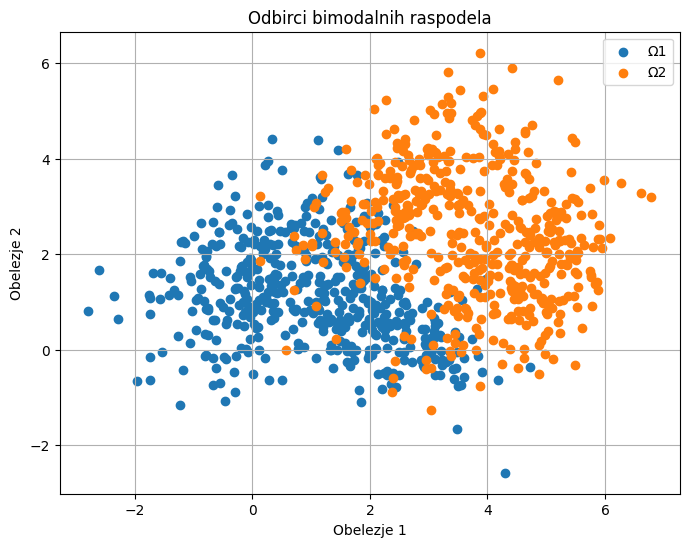

In [3]:
plt.figure(figsize=(8, 6))
plt.scatter(data1[:, 0], data1[:, 1], label="Ω1")
plt.scatter(data2[:, 0], data2[:, 1], label="Ω2")

plt.title("Odbirci bimodalnih raspodela")
plt.xlabel("Obelezje 1")
plt.ylabel("Obelezje 2")
plt.legend()
plt.grid(True)
plt.show()

Teorijska fgv

In [4]:
def gaussian_pdf(X, M, S):
    detS = np.linalg.det(S)
    invS = np.linalg.inv(S)
    f = 1/(2*np.pi*detS**0.5)*np.exp(-0.5*(X-M).T@invS@(X-M))
    return f

# teorijska fgv
x = np.arange(0,10.1,0.1)
y = np.arange(0,10.1,0.1)

f11 = np.zeros((len(x),len(y)))
f12 = np.zeros((len(x),len(y)))
f21 = np.zeros((len(x),len(y)))
f22 = np.zeros((len(x),len(y)))

f1 = np.zeros((len(x),len(y)))
f2 = np.zeros((len(x),len(y)))

for i in range(0,len(x)):
    for j in range(0,len(y)):
        X = np.array([x[i],y[j]]).reshape(-1,1)
        f11[i,j] = gaussian_pdf(X,M11,S11)[0,0]
        f12[i,j] = gaussian_pdf(X,M12,S12)[0,0]
        f21[i,j] = gaussian_pdf(X,M21,S21)[0,0]
        f22[i,j] = gaussian_pdf(X,M22,S22)[0,0]
        
        f1[i,j] = p11*f11[i,j] + p12*f12[i,j]
        f2[i,j] = p21*f21[i,j] + p22*f22[i,j]




Histogram

In [5]:
# prva klasa
hist1, x_edges1, y_edges1 = np.histogram2d(
    data1[:,0], data1[:,1],
    bins=12, range=[[0, 10], [0, 10]], density=True)
x_pos1, y_pos1 = np.meshgrid(x_edges1[:-1], y_edges1[:-1], indexing="ij") # mreža koordinata stubića histograma
x_pos1 = x_pos1.ravel() 
y_pos1 = y_pos1.ravel()
z_pos1 = np.zeros_like(x_pos1) # početna visina svakog stubića
dx1 = dy1 = (x_edges1[1] - x_edges1[0]) # dimenzije ćelija
dz1 = hist1.ravel() # visina ćelija

# druga klasa
hist2, x_edges2, y_edges2 = np.histogram2d(data2[:,0], data2[:,1], bins=20,range=[[0, 10], [0, 10]], density=True)
x_pos2, y_pos2 = np.meshgrid(x_edges2[:-1], y_edges2[:-1], indexing="ij")
x_pos2 = x_pos2.ravel()
y_pos2 = y_pos2.ravel()
z_pos2 = np.zeros_like(x_pos2)
dx2 = dy2 = (x_edges2[1] - x_edges2[0])
dz2 = hist2.ravel()


Crtanje fgv i histograma i poredjenje

/Users/jelenacicvaric/venv/lib/python3.14/site-packages/mpl_toolkits/mplot3d/art3d.py:1403: RuntimeWarning: divide by zero encountered in matmul
  shade = ((normals / np.linalg.norm(normals, axis=1, keepdims=True))
/Users/jelenacicvaric/venv/lib/python3.14/site-packages/mpl_toolkits/mplot3d/art3d.py:1403: RuntimeWarning: overflow encountered in matmul
  shade = ((normals / np.linalg.norm(normals, axis=1, keepdims=True))


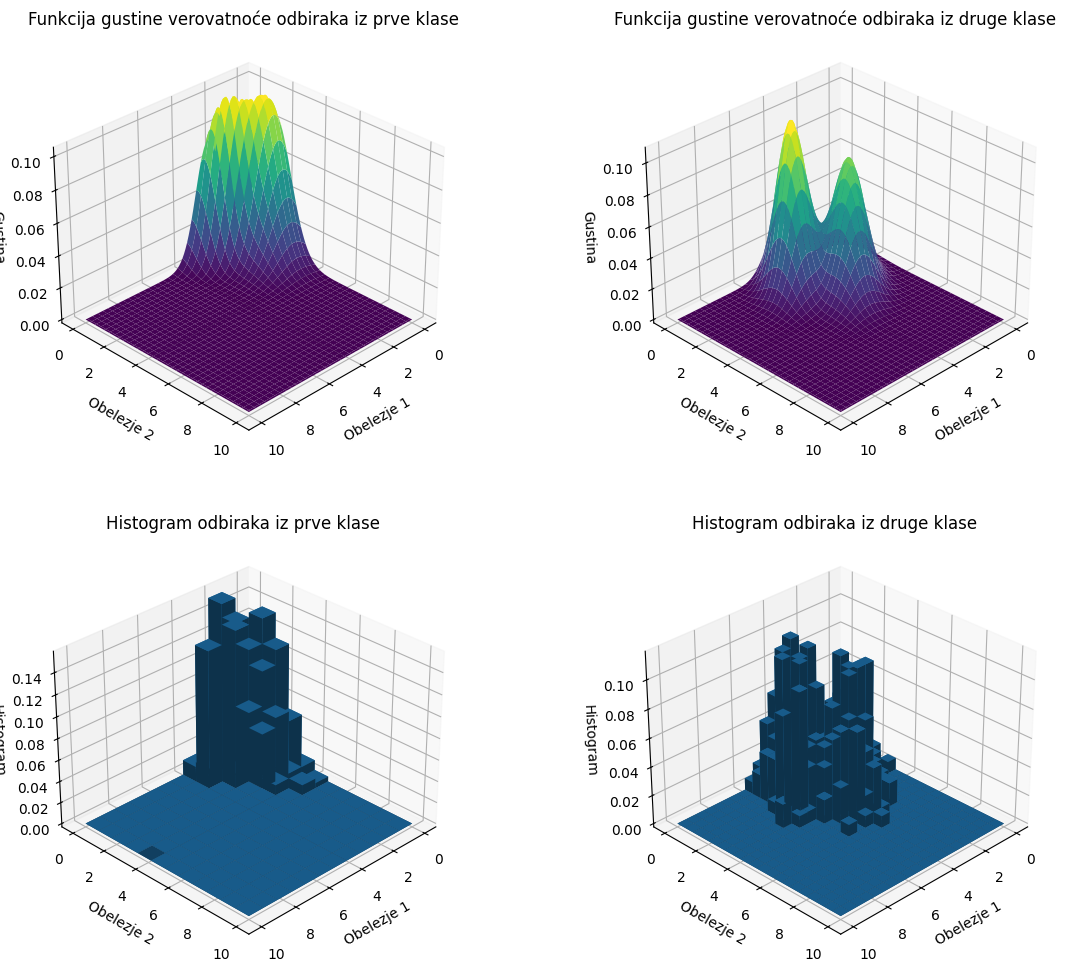

In [6]:
# b)
X, Y = np.meshgrid(x,y)
fig = plt.figure(figsize=(14,12))

ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.plot_surface(X, Y, f1.T, cmap='viridis')
ax1.set_xlabel('Obelezje 1')
ax1.set_ylabel('Obelezje 2')
ax1.set_zlabel('Gustina')
ax1.set_title('Funkcija gustine verovatnoće odbiraka iz prve klase')

ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax2.plot_surface(X, Y, f2.T, cmap='viridis')
ax2.set_xlabel('Obelezje 1')
ax2.set_ylabel('Obelezje 2')
ax2.set_zlabel('Gustina')
ax2.set_title('Funkcija gustine verovatnoće odbiraka iz druge klase')

ax3 = fig.add_subplot(2, 2, 3, projection='3d')
ax3.bar3d(x_pos1, y_pos1, z_pos1, dx1, dy1, dz1, shade=True)
ax3.set_xlabel("Obelezje 1")
ax3.set_ylabel("Obelezje 2")
ax3.set_zlabel("Histogram")
ax3.set_title("Histogram odbiraka iz prve klase")

ax4 = fig.add_subplot(2, 2, 4, projection='3d')
ax4.bar3d(x_pos2, y_pos2, z_pos2, dx2, dy2, dz2, shade=True)
ax4.set_xlabel("Obelezje 1")
ax4.set_ylabel("Obelezje 2")
ax4.set_zlabel("Histogram")
ax4.set_title("Histogram odbiraka iz druge klase")

ax1.view_init(elev=30, azim=45)
ax2.view_init(elev=30, azim=45)
ax3.view_init(elev=30, azim=45)
ax4.view_init(elev=30, azim=45)

plt.show()

Bajesov klasifikator minimalne verovatnoće greške

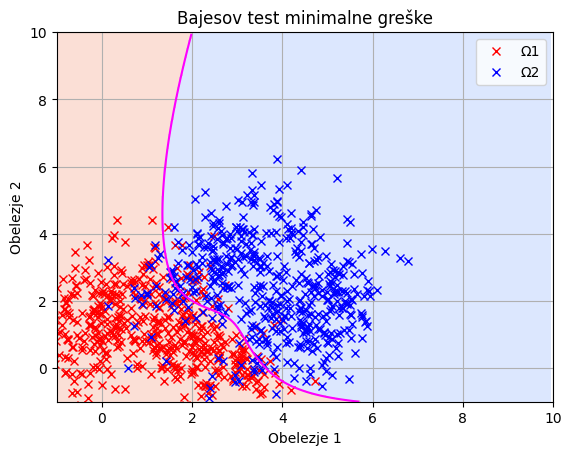

In [7]:
# prag odlučivanja
T = np.log((p11+p12)/(p21+p22))

# računanje diskriminacione funkcije
x = np.arange(-1,10,0.05)
y = np.arange(-1,10,0.05)
h = np.zeros((len(x),len(y)))

f11 = np.zeros((len(x),len(y)))
f12 = np.zeros((len(x),len(y)))
f21 = np.zeros((len(x),len(y)))
f22 = np.zeros((len(x),len(y)))
f1 = np.zeros((len(x),len(y)))
f2 = np.zeros((len(x),len(y)))

for i in range(0,len(x)):
    for j in range(0,len(y)):
        X = np.array([x[i],y[j]]).reshape(-1,1)
        
        f11[i,j] = gaussian_pdf(X,M11,S11)[0,0]
        f12[i,j] = gaussian_pdf(X,M12,S12)[0,0]
        f21[i,j] = gaussian_pdf(X,M21,S21)[0,0]
        f22[i,j] = gaussian_pdf(X,M22,S22)[0,0]
        
        f1[i,j] = p11*f11[i,j] + p12*f12[i,j]
        f2[i,j] = p21*f21[i,j] + p22*f22[i,j]
                
        h[i,j] = -np.log(f1[i,j]/f2[i,j])

# klasifikaciona linija
kl = h.T < T

# crtanje
plt.figure()
plt.plot(data1[:,0], data1[:,1], 'rx', label='Ω1')  
plt.plot(data2[:,0], data2[:,1], 'bx', label='Ω2') 
plt.contour(x, y, h.T, levels=[T], colors='magenta')
plt.contourf(x, y, kl, levels=1, cmap='coolwarm', alpha=0.3)
plt.title('Bajesov test minimalne greške')
plt.xlabel('Obelezje 1')
plt.ylabel('Obelezje 2')
plt.xlim([-1,10])
plt.ylim([-1,10])
plt.legend()
plt.grid(True)
plt.show()

Poređenje greške klasifikacije konkretnih odbiraka sa teorijskom greškom klasifikacije prve i druge vrste

In [8]:
# eksperimentalna greška (konfuziona matrica)
T = np.log((p11+p12)/(p21+p22))
data = np.concatenate((data1,data2),axis=0)
y_real = np.zeros(2*N) 
y_real[N:] = 1
y_predict = np.zeros(np.shape(y_real))

# klasifikacija svih odbiraka
for i in range(0,len(y_real)):
    X = data[i,:].reshape(2,1)
    f11 = gaussian_pdf(X,M11,S11)[0,0]
    f12 = gaussian_pdf(X,M12,S12)[0,0]
    f21 = gaussian_pdf(X,M21,S21)[0,0]
    f22 = gaussian_pdf(X,M22,S22)[0,0]
        
    f1_i = p11*f11 + p12*f12
    f2_i = p21*f21 + p22*f22
                
    h = -np.log(f1_i/f2_i)
    y_predict[i] = h>T
    
cm = confusion_matrix(y_real,y_predict)
eps_e1 = cm[0,1]/sum(cm[0,:]) 
eps_e2 = cm[1,0]/sum(cm[1,:])

# teorijska greška
eps_t1 = 0
eps_t2 = 0
for i in range(0,len(x)):
    for j in range(0,len(y)):
        if -np.log(f1[i,j]/f2[i,j]) < T:
            eps_t2 += f2[i,j]*0.1*0.1  # numericka integracija
        else:
            eps_t1 += f1[i,j]*0.1*0.1

print('Greška prve vrste:')
print('Eksperimentalno: ', eps_e1, 'Teorijski: ', eps_t1)
print('Greška druge vrste:')
print('Eksperimentalno: ', eps_e2, 'Teorijski: ', eps_t2)

Greška prve vrste:
Eksperimentalno:  0.068 Teorijski:  0.3058141397101743
Greška druge vrste:
Eksperimentalno:  0.104 Teorijski:  0.4616418475598564


Bajesov klasifikator minimalne cene

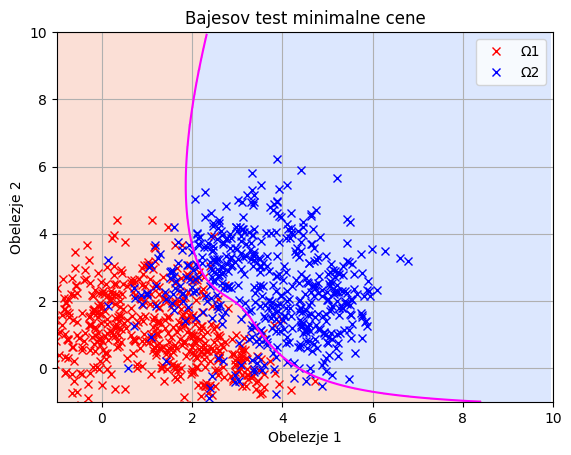

In [9]:
# cene i prag odlučivanja
c11, c22 = 0, 0
c12 = 1
c21 = 5
T = np.log((p11+p12)/(p21+p22)*(c21-c11)/(c12-c22))

# računanje diskriminacione funkcije
x = np.arange(-1,10,0.05)
y = np.arange(-1,10,0.05)

h = np.zeros((len(x),len(y)))

f11 = np.zeros((len(x),len(y)))
f12 = np.zeros((len(x),len(y)))
f21 = np.zeros((len(x),len(y)))
f22 = np.zeros((len(x),len(y)))
f1 = np.zeros((len(x),len(y)))
f2 = np.zeros((len(x),len(y)))

for i in range(0,len(x)):
    for j in range(0,len(y)):
        X = np.array([x[i],y[j]]).reshape(2,1)
        f11[i,j] = gaussian_pdf(X,M11,S11)[0,0]
        f12[i,j] = gaussian_pdf(X,M12,S12)[0,0]
        f21[i,j] = gaussian_pdf(X,M21,S21)[0,0]
        f22[i,j] = gaussian_pdf(X,M22,S22)[0,0]
        
        f1[i,j] = p11*f11[i,j] + p12*f12[i,j]
        f2[i,j] = p21*f21[i,j] + p22*f22[i,j]
                
        h[i,j] = -np.log(f1[i,j]/f2[i,j])

# klasifikaciona linija
kl = h.T < T

# crtanje
plt.figure()
plt.plot(data1[:,0], data1[:,1], 'rx', label='Ω1')  
plt.plot(data2[:,0], data2[:,1], 'bx', label='Ω2') 
plt.contour(x, y, h.T, levels=[T], colors='magenta')
plt.contourf(x, y, kl, levels=1, cmap='coolwarm', alpha=0.3)
plt.title('Bajesov test minimalne cene')
plt.xlabel('Obelezje 1')
plt.ylabel('Obelezje 2')
plt.xlim([-1,10])
plt.ylim([-1,10])
plt.legend()
plt.grid(True)
plt.show()

Neumann–Pearsonov klasifikator

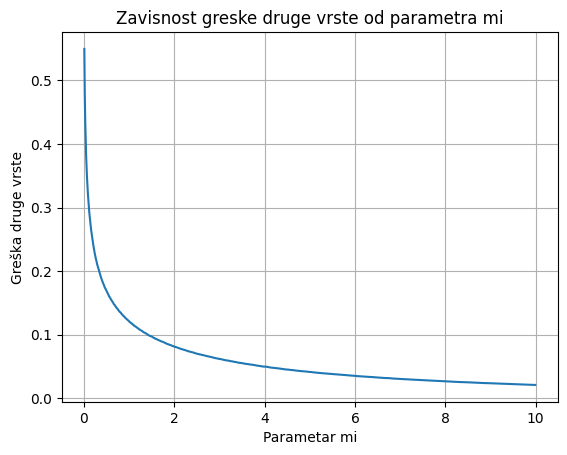

In [10]:
# diskriminaciona f-ja
x = np.arange(-1,10,0.05)
y = np.arange(-1,10,0.05)

f11 = np.zeros((len(x),len(y)))
f12 = np.zeros((len(x),len(y)))
f21 = np.zeros((len(x),len(y)))
f22 = np.zeros((len(x),len(y)))
f1 = np.zeros((len(x),len(y)))
f2 = np.zeros((len(x),len(y)))

h = np.zeros((len(x),len(y)))
for i in range(0,len(x)):
    for j in range(0,len(y)):
        X = np.array([x[i],y[j]]).reshape(2,1)
        f11[i,j] = gaussian_pdf(X,M11,S11)[0,0]
        f12[i,j] = gaussian_pdf(X,M12,S12)[0,0]
        f21[i,j] = gaussian_pdf(X,M21,S21)[0,0]
        f22[i,j] = gaussian_pdf(X,M22,S22)[0,0]
        f1[i,j] = p11*f11[i,j] + p12*f12[i,j]
        f2[i,j] = p21*f21[i,j] + p22*f22[i,j]
        h[i,j] = -np.log(f1[i,j]/f2[i,j])

br = 0
mi = np.arange(0.01,10,0.01)
eps2 = np.zeros(len(mi))
for m in range(0,len(mi)):
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            if h[i,j]<-np.log(mi[m]):
                eps2[m] = eps2[m] + 0.05*0.05*(f2[i,j]+f2[i+1,j]+f2[i,j+1]+f2[i+1,j+1])/4
            
plt.figure()
plt.plot(mi,eps2)
plt.xlabel('Parametar mi')
plt.ylabel('Greška druge vrste')
plt.title('Zavisnost greske druge vrste od parametra mi')
plt.grid(True)
plt.show()

eps0 = 0.02
odabrano mi = 9.99 daje eps2 ≈ 0.02117927080423235


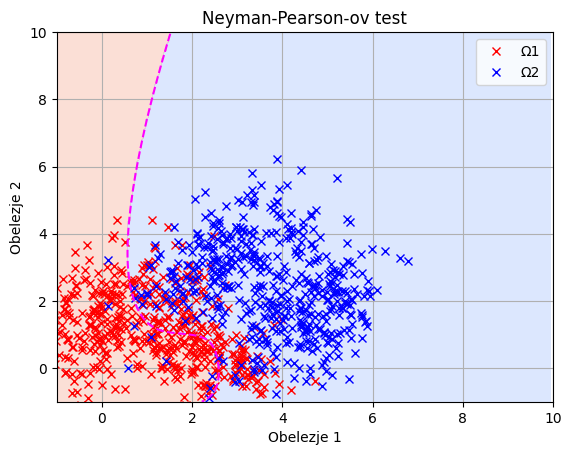

In [11]:
eps0 = 0.02
idx = np.argmin(np.abs(eps2 - eps0))
mi_opt = mi[idx]
T = -np.log(mi_opt)

print("eps0 =", eps0)
print("odabrano mi =", mi_opt, "daje eps2 ≈", eps2[idx])

# prag odlučivanja
T = -np.log(mi_opt)

# diskriminaciona f-ja
x = np.arange(-1,10,0.05)
y = np.arange(-1,10,0.05)

h = np.zeros((len(x),len(y)))

f11 = np.zeros((len(x),len(y)))
f12 = np.zeros((len(x),len(y)))
f21 = np.zeros((len(x),len(y)))
f22 = np.zeros((len(x),len(y)))
f1 = np.zeros((len(x),len(y)))
f2 = np.zeros((len(x),len(y)))

for i in range(0,len(x)):
    for j in range(0,len(y)):
        X = np.array([x[i],y[j]]).reshape(2,1)
        f11[i,j] = gaussian_pdf(X,M11,S11)[0,0]
        f12[i,j] = gaussian_pdf(X,M12,S12)[0,0]
        f21[i,j] = gaussian_pdf(X,M21,S21)[0,0]
        f22[i,j] = gaussian_pdf(X,M22,S22)[0,0]
        
        f1[i,j] = p11*f11[i,j] + p12*f12[i,j]
        f2[i,j] = p21*f21[i,j] + p22*f22[i,j]
                
        h[i,j] = -np.log(f1[i,j]/f2[i,j])


kl = h.T < T

# crtanje
plt.figure()
plt.plot(data1[:,0], data1[:,1], 'rx', label='Ω1')  
plt.plot(data2[:,0], data2[:,1], 'bx', label='Ω2') 
plt.contour(x, y, h.T, levels=[T], colors='magenta')
plt.contourf(x, y, kl, levels=1, cmap='coolwarm', alpha=0.3)
plt.title('Neyman-Pearson-ov test')
plt.xlabel('Obelezje 1')
plt.ylabel('Obelezje 2')
plt.xlim([-1,10])
plt.ylim([-1,10])
plt.legend()
plt.grid(True)
plt.show()

Waldov sekvencijalni test

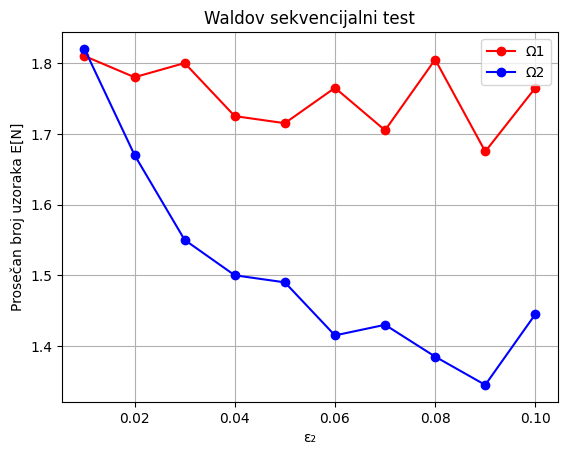

In [14]:

eps1 = 0.05                              
eps2_vals = np.linspace(0.01, 0.1, 10)   
num_trials = 200                         # broj ponavljanja

avg_samples_1 = []
avg_samples_2 = []
max_iter = 1000
tiny = 1e-10  # da se izbegne deljenje nulom
for eps2 in eps2_vals:
    # granice odlučivanja
    a = np.log((1 - eps2) / eps1)
    b = np.log(eps2 / (1 - eps1))

    samples_1 = []
    samples_2 = []

    for _ in range(num_trials):

        Sm = 0
        for m in range(1, max_iter + 1):

            # generisanje uzorka iz prve klase
            if np.random.rand() < p11:
                X = np.random.multivariate_normal(M11.flatten(), S11).reshape(2,1)
            else:
                X = np.random.multivariate_normal(M12.flatten(), S12).reshape(2,1)

            f1 = p11*gaussian_pdf(X, M11, S11) + p12*gaussian_pdf(X, M12, S12)
            f2 = p21*gaussian_pdf(X, M21, S21) + p22*gaussian_pdf(X, M22, S22)

            Sm += np.log((f1 + tiny) / (f2 + tiny))

            if Sm >= a or Sm <= b:
                samples_1.append(m)
                break

        Sm = 0
        for m in range(1, max_iter + 1):

            # generisanje uzorka iz druge klase
            if np.random.rand() < p21:
                X = np.random.multivariate_normal(M21.flatten(), S21).reshape(2,1)
            else:
                X = np.random.multivariate_normal(M22.flatten(), S22).reshape(2,1)

            f1 = p11*gaussian_pdf(X, M11, S11) + p12*gaussian_pdf(X, M12, S12)
            f2 = p21*gaussian_pdf(X, M21, S21) + p22*gaussian_pdf(X, M22, S22)

            Sm += np.log((f1 + tiny) / (f2 + tiny))

            if Sm >= a or Sm <= b:
                samples_2.append(m)
                break

    avg_samples_1.append(np.mean(samples_1))
    avg_samples_2.append(np.mean(samples_2))

# crtanje
plt.figure()
plt.plot(eps2_vals, avg_samples_1, 'r-o', label='Ω1')
plt.plot(eps2_vals, avg_samples_2, 'b-o', label='Ω2')
plt.xlabel('ε₂')
plt.ylabel('Prosečan broj uzoraka E[N]')
plt.title('Waldov sekvencijalni test')
plt.grid(True)
plt.legend()
plt.show()

Zavisnost broja potrebnih odbiraka od usvojene verovatnoće grešaka prvog, odnosno drugog tipa

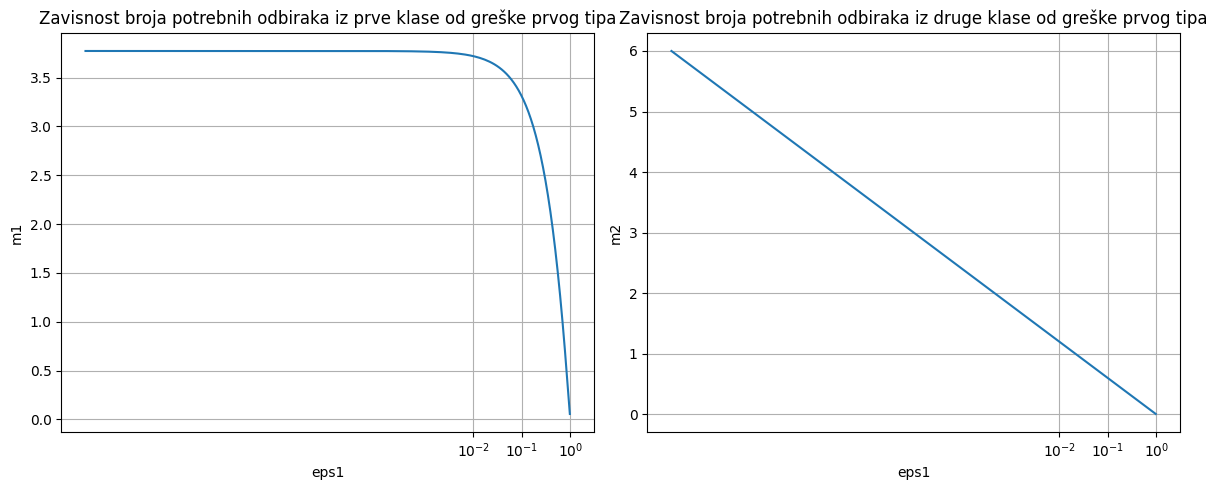

In [ ]:
# broj obeležja i srednje vrednosti
feat_num = 2
ni1, ni2 = 0, 0

for j in range(feat_num):
    X1 = data1[j,:].reshape(2,1)
    f11 = gaussian_pdf(X1,M11,S11)[0,0]
    f12 = gaussian_pdf(X1,M12,S12)[0,0]
    f1 = p11 * f11 + p12 * f12
    
    f21 = gaussian_pdf(X1,M21,S21)[0,0]
    f22 = gaussian_pdf(X1,M22,S22)[0,0]
    f2 = p21 * f21 + p22 * f22
    
    ni1 -= np.log(f1 / f2) / feat_num
    
    X2 = data2[j,:].reshape(2,1)
    f11 = gaussian_pdf(X2,M11,S11)[0,0]
    f12 = gaussian_pdf(X2,M12,S12)[0,0]
    f1 = p11 * f11 + p12 * f12
    
    f21 = gaussian_pdf(X2,M21,S21)[0,0]
    f22 = gaussian_pdf(X2,M22,S22)[0,0]
    f2 = p21 * f21 + p22 * f22
    
    ni2 -= np.log(f1 / f2) / feat_num


# zavisnost broja odbiraka od greške prvog tipa dok je greška drugog tipa const
eps2 = 0.000001
eps1 = np.logspace(-10, -0.01, 200)

m1 = (-np.log((1 - eps1) / eps2) * (1 - eps1) - np.log(eps1 / (1 - eps2)) * eps1) / ni1
m2 = (-np.log(eps1 / (1 - eps2)) * (1 - eps2) - np.log((1 - eps1) / eps2) * eps2) / ni2
m1 = m1.reshape(-1,1)
m2 = m2.reshape(-1,1)

# iscrtavanje
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.semilogx(eps1, m1)
plt.xlabel('eps1')
plt.ylabel('m1')
plt.xticks([10 ** -2, 10 ** -1, 10 ** 0])
plt.title('Zavisnost broja potrebnih odbiraka iz prve klase od greške prvog tipa')
plt.grid(True)


plt.subplot(1, 2, 2)
plt.semilogx(eps1, m2)
plt.xlabel('eps1')
plt.ylabel('m2')
plt.xticks([10 ** -2, 10 ** -1, 10 ** 0])
plt.title('Zavisnost broja potrebnih odbiraka iz druge klase od greške prvog tipa')
plt.grid(True)

plt.tight_layout()
plt.show()

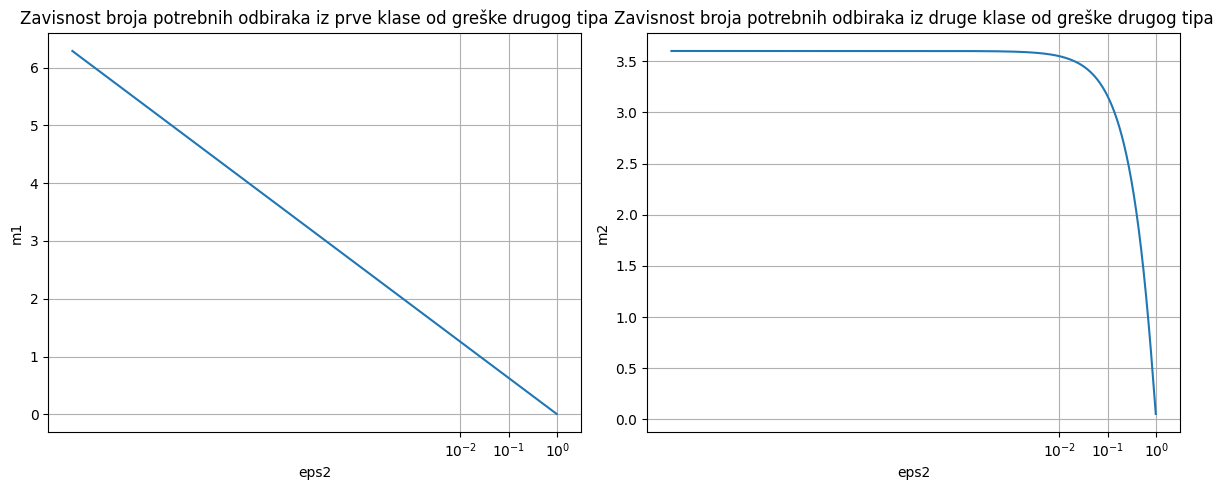

In [ ]:
# zavisnost broja odbiraka od greške drugog tipa dok je greška prvog tipa const
eps1 = 0.000001
eps2 = np.logspace(-10, -0.01, 200)

m1 = (-np.log((1 - eps1) / eps2) * (1 - eps1) - np.log(eps1 / (1 - eps2)) * eps1) / ni1
m2 = (-np.log(eps1 / (1 - eps2)) * (1 - eps2) - np.log((1 - eps1) / eps2) * eps2) / ni2
m1 = m1.reshape(-1,1)
m2 = m2.reshape(-1,1)

#iscrtavanje
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.semilogx(eps2, m1)
plt.xlabel('eps2')
plt.ylabel('m1')
plt.xticks([10 ** -2, 10 ** -1, 10 ** 0])
plt.title('Zavisnost broja potrebnih odbiraka iz prve klase od greške drugog tipa')
plt.grid(True)


plt.subplot(1, 2, 2)
plt.semilogx(eps2, m2)
plt.xlabel('eps2')
plt.ylabel('m2')
plt.xticks([10 ** -2, 10 ** -1, 10 ** 0])
plt.title('Zavisnost broja potrebnih odbiraka iz druge klase od greške drugog tipa')
plt.grid(True)

plt.tight_layout()
plt.show()
